# Fraud detection project 

Building a supervised machine learning model classifier that learns from past examples where answer is already known. Model will be implemented using synthetic paysim data

### Load data:

In [ ]:

import pandas as pd 
data = pd.read_csv("../data/transaction_data.csv")


## Exploratory data analysis

In [17]:
data.shape

(6362620, 11)

In [18]:
data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [19]:
data.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   step            6362620 non-null  int64  
 1   type            6362620 non-null  object 
 2   amount          6362620 non-null  float64
 3   nameOrig        6362620 non-null  object 
 4   oldbalanceOrg   6362620 non-null  float64
 5   newbalanceOrig  6362620 non-null  float64
 6   nameDest        6362620 non-null  object 
 7   oldbalanceDest  6362620 non-null  float64
 8   newbalanceDest  6362620 non-null  float64
 9   isFraud         6362620 non-null  int64  
 10  isFlaggedFraud  6362620 non-null  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [20]:
data.nunique()

step                  743
type                    5
amount            5316900
nameOrig          6353307
oldbalanceOrg     1845844
newbalanceOrig    2682586
nameDest          2722362
oldbalanceDest    3614697
newbalanceDest    3555499
isFraud                 2
isFlaggedFraud          2
dtype: int64

### Unique values: findings

- **nameOrig**: 99.85% unique, so almost every sender appears once. There's no sender history to learn from.
- **nameDest**: 2.72M unique values across 6.36M rows (~2.3 transactions each). Destinations repeat, so we can build history features, e.g. how many times an account has been paid before. That could flag mule accounts receiving from many victims.
- **Past only**: history features must count only earlier transactions (lower `step`). Counting future rows would leak information the bank wouldn't have at prediction time.
- **Raw IDs** aren't used as features. The model would memorise accounts and fail on new ones (overfitting).  <-- (why??)
- **step**: 1 step = 1 hour; 743 steps ≈ 31 days. It defines "past" for history features.
- **type**: 5 categories (PAYMENT, TRANSFER, CASH_OUT, DEBIT, CASH_IN). Text, so it needs encoding into numbers before modelling.

In [40]:
# class balance

n_total = data["isFraud"].size
n_fraud = (data["isFraud"] == 1).sum()
n_genuine = (data["isFraud"]== 0).sum()
fraud_ratio = n_fraud/n_total
nonFraud_ratio = n_genuine/n_total

print(f'percentage of fraudulent transactions in data set is {fraud_ratio:.3%}')
print(f'percentage of non-fraudulent transactions in data is {nonFraud_ratio:.3%}')

percentage of fraudulent transactions in data set is 0.129%
percentage of non-fraudulent transactions in data is 99.871%


 A data set where 0.129 % of transactiosna are fraudulent means an always-“not fraud” model scores 99.87% accuracy but catches 0% of fraud (recall = 0). Accuracy is dominated by the majority class, so on imbalanced data it hides failure on the class we care about. We use recall, precision and PR AUC instead.  (need to find out what PR AUC means)

### Distributions

PROPORTION OF DIFFERENT TRANSACTION TYPES:

In [118]:
payment_count = (data["type"] == "PAYMENT").sum()
transfer_count = (data["type"] == "TRANSFER").sum()
cashin_count = (data["type"] == "CASH_IN").sum()
cashout_count = (data["type"] == "CASH_OUT").sum()
debit_count = (data["type"] == "DEBIT").sum()


print(f'number of payment transactions: {payment_count}')
print(f"number of transfer transactions: {transfer_count}")
print(f"number of cash_in transactipns: {cashin_count} ")
print(f"number of cash_out transactions: {cashout_count}")
print(f"number of debit transactions: {debit_count}")
print("-------------------------")
print(f'percentage of total transcation that were payments: {payment_count/len(data):.3%}')
print(f'percentage of total transactions that were transfers: {transfer_count/len(data):.3%}')
print(f'percentage of total transactions that were cash_in: {cashin_count/len(data):.3%}')
print(f'percentage of total transactions that were cash_out: {cashout_count/len(data):.3%}')
print(f'percentage of total transactions that were debit: {debit_count/len(data):.3%}')



number of payment transactions: 2151495
number of transfer transactions: 532909
number of cash_in transactipns: 1399284 
number of cash_out transactions: 2237500
number of debit transactions: 41432
-------------------------
percentage of total transcation that were payments: 33.815%
percentage of total transactions that were transfers: 8.376%
percentage of total transactions that were cash_in: 21.992%
percentage of total transactions that were cash_out: 35.166%
percentage of total transactions that were debit: 0.651%


In [ ]:
# easier way to do proportion calculations:

data["type"].value_counts(normalize=True)

type
CASH_OUT    0.351663
PAYMENT     0.338146
CASH_IN     0.219923
TRANSFER    0.083756
DEBIT       0.006512
Name: proportion, dtype: float64

PERCENTAGE OF FRAUD FLAGS PER TRANSACTION TYPE:

In [108]:
payment_txns = data[data["type"] == "PAYMENT"]
fraud_payment_txns = (payment_txns["isFraud"] == 1)

transfer_txns = data[data["type"] == "TRANSFER"]
fraud_transfer_txns = transfer_txns["isFraud"] == 1 

cashin_txns = data[data["type"] == "CASH_IN"]
fraud_cashin_txns = cashin_txns["isFraud"] == 1 

cashout_txns = data[data["type"] == "CASH_OUT"]
fraud_cashout_txns = cashout_txns["isFraud"] == 1 

debit_txns = data[data["type"] == "DEBIT"]
fraud_debit_txns = debit_txns["isFraud"] == 1 


pct_payment_txn = fraud_payment_txns.sum()/len(payment_txns)
pct_transfer_txns = fraud_transfer_txns.sum()/len(transfer_txns)
pct_cashin_txns = fraud_cashin_txns.sum()/len(cashin_txns)
pct_cashout_txns = fraud_cashout_txns.sum()/len(cashout_txns)
pct_debit_txns = fraud_debit_txns.sum()/len(debit_txns)


print("Fraud percentages in different transaction types:")
print("-------------------------------------------------")
print(f'percentage of fraudulent payment transactions: {pct_payment_txn:.3%}')
print(f'percentage of fraudulent transfer transactions: {pct_transfer_txns:.3%}')
print(f'percentage of fraudulent cash_in transactions: {pct_cashin_txns:.3%}')
print(f'percentage of fraudulent cash_out transactions: {pct_cashout_txns:.3%}')
print(f'percentage of fraudulent debit transactions: {pct_debit_txns:.3%}')



Fraud percentages in different transaction types:
-------------------------------------------------
percentage of fraudulent payment transactions: 0.000%
percentage of fraudulent transfer transactions: 0.769%
percentage of fraudulent cash_in transactions: 0.000%
percentage of fraudulent cash_out transactions: 0.184%
percentage of fraudulent debit transactions: 0.000%


In [120]:
# easier proportion calculation for fraid om different transaction types

data.groupby("type")["isFraud"].mean()

type
CASH_IN     0.000000
CASH_OUT    0.001840
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.007688
Name: isFraud, dtype: float64

Fraud flags were ony raised for cash out and transfer type transactions, with transfer transactions having a siginificantly higher fraud rate than cash out
The bigger implication for the model - Because fraud never occurs as payments, debits or cash in, the data can be filtered to transfer and cash out only. The pros and cons are:
- pros: retaining all fraud information while dropping 56% of rows allows faster training. proportion of fraud incidents in the data would rise to 30% as oppose to 0.129%
- cons: the model onlty covers two transaction types - (decide on wether to filter or not)


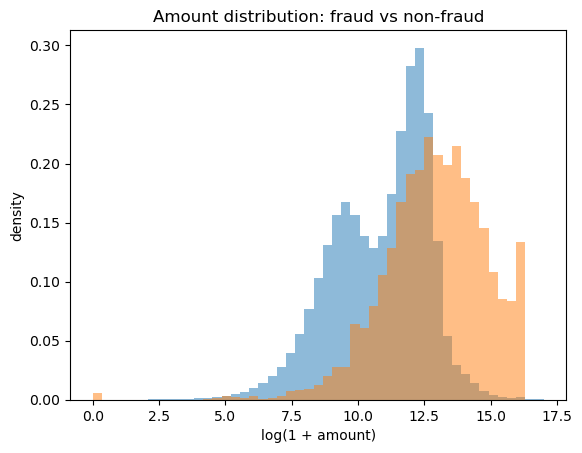

In [135]:
import matplotlib.pyplot as plt
import numpy as np


non_fraud_txn_amount = data.loc[data["isFraud"] == 0, "amount"].sort_values()
fraud_txn_amount = data.loc[data["isFraud"] == 1, "amount"].sort_values()

bins = np.linspace(0, 17, 50) 

plt.hist(np.log1p(non_fraud_txn_amount), bins=bins, density=True, alpha=0.5, label="genuine")
plt.hist(np.log1p(fraud_txn_amount), bins=bins, density=True, alpha=0.5, label="fraud")
plt.xlabel("log(1 + amount)")
plt.ylabel("density")
plt.title("Amount distribution: fraud vs non-fraud")
plt.show()

In [ ]:
# max fraud amount 
print(f'Max fraud transaction amaount: {fraud_txn_amount.max()}')
print(f'Max non-fraud transaction amaount: {non_fraud_txn_amount.max()}')

Max fraud transaction amaount: 10000000.0
Max non-fraud transaction amaount: 92445516.64


In [ ]:
# number of fraudulent transactions with amount 0
(fraud_txn_amount == 0).sum()

16

### Leakage calculation 

In [141]:
from sklearn.metrics import roc_auc_score

numeric_cols = ["step", "amount", "oldbalanceOrg", "newbalanceOrig",
                "oldbalanceDest", "newbalanceDest", "isFlaggedFraud"]

for col in numeric_cols:
    auc = roc_auc_score(data["isFraud"], data[col])
    auc = max(auc, 1 - auc)      # direction doesn't matter, only strength
    print(f"{col:16} {auc:.3f}")

step             0.667
amount           0.790
oldbalanceOrg    0.811
newbalanceOrig   0.704
oldbalanceDest   0.632
newbalanceDest   0.540
isFlaggedFraud   0.501


### Leakage check: findings

**Logic test:** every remaining column is known when the transaction happens, and none is created from the fraud outcome.

**Data test** (single-column ROC AUC; 0.5 = no signal, 1.0 = perfect):
- No column exceeds 0.95, so there's no evidence of single-column leakage.
- Strongest signals: `oldbalanceOrg` (0.81) and `amount` (0.79). Fraud tends to move large sums and empty the account.
- `isFlaggedFraud` = 0.50: the bank's existing rule has essentially no detection power.
- `step` = 0.67: timing carries some signal; explore in feature engineering.

**Decisions:**
- Drop `isFlaggedFraud` (redundant rule on amount; no signal). Keep it only as a comparison against the model.
- Drop raw `nameOrig` / `nameDest` (IDs would be memorised). Destination-history features may be built later from earlier steps only.
- Keep `step`, `type`, `amount` and the four balance columns.